# Problem 13

In [1]:
import casadi as ca

opti = ca.Opti()

# Zielvariablen
x = opti.variable()
y = opti.variable()

# Zielfuntkion und NB
opti.minimize((x-2)**2 + y**2)
opti.subject_to((1-x)**3-y > 0)
opti.subject_to(x>=0)
opti.subject_to(y>=0)

# Solver, init
opti.solver('ipopt')
opti.set_initial(x, -2)
opti.set_initial(y, -2)
sol = opti.solve()

print(round(sol.value(x),6))
print(round(sol.value(y),6))


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.19, running with linear solver MUMPS 5.8.2.

Number of nonzeros in equality constraint Jacobian...:        0
Number of nonzeros in inequality constraint Jacobian.:        4
Number of nonzeros in Lagrangian Hessian.............:        2

Total number of variables............................:        2
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:        0
Total number of inequality c

# Problem 43

In [2]:
import casadi as ca

opti = ca.Opti()

# Zielvariablen
x = opti.variable(4)

# Zielfuntkion und NB
opti.minimize(x[0]**2 + x[1]**2 + 2*x[2]**2 + x[3]**2 - 5 * x[0] - 5*x[1] - 21*x[2] + 7 * x[3])
opti.subject_to(8 - x[0]**2 - x[1]**2 - x[2]**2 - x[3]**2 - x[0] + x[1] - x[2] + x[3] >= 0)
opti.subject_to(10 - x[0]**2 - 2*x[1]**2 - x[2]**2 - 2*x[3]**2 + x[0] + x[3] >= 0)
opti.subject_to(5 - 2*x[0]**2 - x[1]**2 - x[2]**2 - 2*x[0] + x[1] + x[3] >= 0)

# Solver, init
n = 10
x_s = [0,0,0,0]
x_0 = x_s
results = []

for i in range(10):
    opti.solver('ipopt')
    opti.set_initial(x, x_0)
    sol = opti.solve()
    results.append(sol.value(x))
    for j in range(len(x_0)):
        x_0[j] += 1


#for i,value in enumerate(sol.value(x)):
#    print(f'x_{i}: {round(value,3)}')

for i, value in enumerate(results):
    print(f'{i+1}: {value}')

This is Ipopt version 3.14.19, running with linear solver MUMPS 5.8.2.

Number of nonzeros in equality constraint Jacobian...:        0
Number of nonzeros in inequality constraint Jacobian.:       12
Number of nonzeros in Lagrangian Hessian.............:        4

Total number of variables............................:        4
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:        0
Total number of inequality constraints...............:        3
        inequality constraints with only lower bounds:        3
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  0.0000000e+00 0.00e+00 1.31e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

In [3]:
x

MX(opti1_x_1)

# Gerade-strecke

f(u)

g(u)

In [5]:
import casadi as ca

opti = ca.Opti()
n = 2

# Bekannte Parameter
L = 100.0
dL = L/n
xStart = 2.5
vStart = 1.0

B = 4.0
m = 790.0
alpha = 0.001872

F_MotorMax = 10410.0
F_HaftMax = 8000.0



# Zielvariablen
u = opti.variable(2*n)

x = u[0:n]
v = u[n:2*n]

# Strecke
s = ca.vertcat(
    ca.sqrt(dL**2+(xStart-x[0])**2),
    ca.sqrt(dL**2+(x[1]-x[0])**2)
)

# Hindernis
y_hindernis = 70.0
b = 3.5
c = B
eps = 0.01

if not 0 <= y_hindernis <= L:
    raise ValueError("Das Hindernis muss zwischen y=0 und y=L liegen.")

x_stuetzpunkte = ca.vertcat(xStart, x)
segment = min(int(y_hindernis / dL), n - 1)
t = (y_hindernis - segment * dL) / dL
x_am_hindernis = (1 - t) * x_stuetzpunkte[segment] + t * x_stuetzpunkte[segment + 1]

opti.subject_to(
    opti.bounded(b + eps, x_am_hindernis, c - eps)
)

# mittlere Geschwindigkeiten
vm = ca.vertcat(
    (v[0] + vStart) / 2,
    (v[1] + v[0]) / 2
)

# Zeitdif
dt = s / vm

# Änderung der Geschwindigkeit
dv = ca.vertcat(
    v[0] - vStart,
    v[1] - v[0]
)

# Beschleunigungen und Kräfte
aBahn = dv / dt

F_Brems_Motor = m * (aBahn + alpha * vm**2)
F_Reifen = m * aBahn

# Zielfunktion
f = dt[0] + dt[1]
opti.minimize(f)

# NB1 und NB2
opti.subject_to(F_Brems_Motor <= F_MotorMax)

# NB3 und NB4
opti.subject_to(opti.bounded(-F_HaftMax, F_Reifen, F_HaftMax))

# Box-Constraints
opti.subject_to(opti.bounded(0, x, B))
opti.subject_to(v >= 0.001)

# Startwerte
opti.set_initial(u, [xStart, xStart, vStart, vStart])

opti.solver("ipopt")
sol = opti.solve()

print("x* =", sol.value(x))
print("v* =", sol.value(v))
print("dt* =", sol.value(dt))
print("T* =", sol.value(f))
print("F_Brems_Motor =", sol.value(F_Brems_Motor))
print("F_Reifen =", sol.value(F_Reifen))

This is Ipopt version 3.14.19, running with linear solver MUMPS 5.8.2.

Number of nonzeros in equality constraint Jacobian...:        0
Number of nonzeros in inequality constraint Jacobian.:       18
Number of nonzeros in Lagrangian Hessian.............:       10

Total number of variables............................:        4
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:        0
Total number of inequality constraints...............:        9
        inequality constraints with only lower bounds:        2
   inequality constraints with lower and upper bounds:        5
        inequality constraints with only upper bounds:        2

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.0000000e+02 1.01e+00 1.74e+00  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

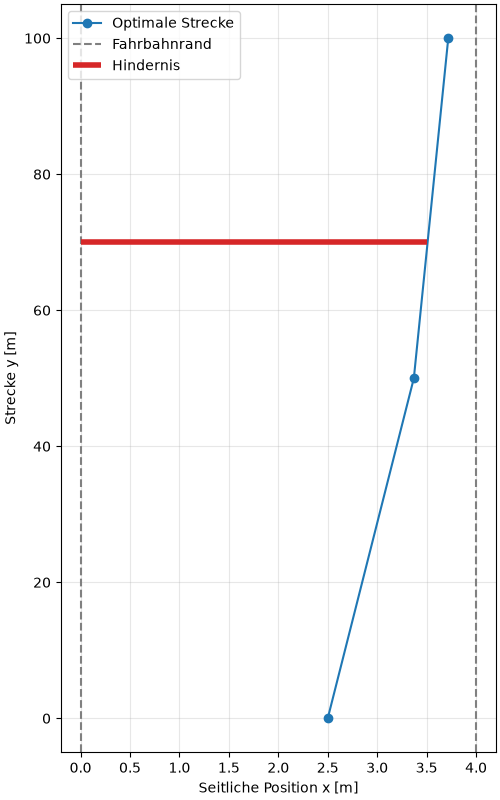

In [6]:
import matplotlib.pyplot as plt

x_opt = sol.value(x).ravel()
y_stuetzpunkte = [i * dL for i in range(n + 1)]
_, ax = plt.subplots(figsize=(5, 8), layout="constrained")
ax.plot([xStart, *x_opt], y_stuetzpunkte, "o-", label="Optimale Strecke")
ax.axvline(0, color="gray", linestyle="--", label="Fahrbahnrand")
ax.axvline(B, color="gray", linestyle="--")
ax.plot(
    [0, b], [y_hindernis, y_hindernis],
    color="tab:red", linewidth=4, solid_capstyle="butt", label="Hindernis",
)
ax.set(xlabel="Seitliche Position x [m]", ylabel="Strecke y [m]")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.show()